# Teste de validação do ambiente de Data Science

In [ ]:
# Loading required libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn.linear_model as LinearRegression

O primeiro exercício consiste em **gerar um array de número aleatórios com Numpy** para utilizar como dados de teste. ps dpos arrays gerados serão: horas_estudo e nota_exame, testando a relação entre a variável de horas estudas e nota numa prova

In [6]:
np.random.seed(42) # seed que garante reprodutibilidade dos resultados

# gerando o array horas_estudo
horas_estudo = np.array([1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20]).reshape(-1, 1) # reshape para transformar em array 2D

# gerando o array nota_exame
nota_exame = np.array(horas_estudo.flatten() * 10 + np.random.normal(0, 5, 20)) # adicionando ruído normal

print("Horas de estudo:\n", horas_estudo)
print("Nota do exame:\n", nota_exame)

Horas de estudo:
 [[ 1]
 [ 2]
 [ 3]
 [ 4]
 [ 5]
 [ 6]
 [ 7]
 [ 8]
 [ 9]
 [10]
 [11]
 [12]
 [13]
 [14]
 [15]
 [16]
 [17]
 [18]
 [19]
 [20]]
Nota do exame:
 [ 12.48357077  19.30867849  33.23844269  47.61514928  48.82923313
  58.82931522  77.89606408  83.83717365  87.65262807 102.71280022
 107.68291154 117.67135123 131.20981136 130.43359878 141.37541084
 157.18856235 164.9358444  181.57123666 185.45987962 192.93848149]


In [7]:
# Estruturando os dados num DataFrame com Pandas
df = pd.DataFrame({
    'Horas de Estudo': horas_estudo.flatten(), 
    'Nota do Exame': nota_exame})

print(df.head())  # Exibindo as primeiras linhas do DataFrame

   Horas de Estudo  Nota do Exame
0                1      12.483571
1                2      19.308678
2                3      33.238443
3                4      47.615149
4                5      48.829233


Agora que temos um dataframe com as relações entre horas estudas e nota tirada na prova, vamos ver um modelo simples de regressão linear com o Scikit-Learn.

**Definição de regressão linear:**

*"Regressão Linear é um modelo estatístico e de machine learning supervisionado que traça uma linha reta para prever um valor numérico contínuo ($y$) a partir de uma variável de entrada ($x$).O algoritmo encontra o melhor ajuste aos dados ao minimizar a distância quadrática entre cada ponto real e a reta calculada (método dos Mínimos Quadrados Ordinários).Na prática, a sua equação fundamental é $y = ax + b$, onde $a$ define a inclinação (o impacto direto de $x$ sobre o resultado) e $b$ representa o ponto de partida inicial da reta."*

In [8]:
modelo = LinearRegression.LinearRegression() # Instanciando o modelo de regressão linear
# utilizando o nome do pacote para chamar a função LinearRegression, pois o nome do pacote é o mesmo da função. Deixando o parenteses vazio para instanciar o modelo com os parâmetros padrão.

modelo.fit(horas_estudo, nota_exame) # Treinando o modelo com os dados de horas de estudo e nota do exame
# Como funciona: insira nos parenteses os dados de treinamento do modelo, sendo o primeiro parâmetro as variáveis independentes (X) e o segundo parâmetro a variável dependente (y).

df['Nota Prevista'] = modelo.predict(horas_estudo) # Adicionando a coluna de notas previstas ao DataFrame
# para adicionar colunas num dataframe colocar o nome do dataframe, colchetes com o nome da coluna e o sinal de igual. No lado direito do sinal de igual colocar a função predict do modelo treinado, passando como parâmetro os dados de entrada (X) para gerar as previsões.

In [9]:
df.head()  # Exibindo as primeiras linhas do DataFrame atualizado com a coluna de notas previstas

,Horas de Estudo,Nota do Exame,Nota Prevista
0,1,12.483571,13.872833
1,2,19.308678,23.375009
2,3,33.238443,32.877186
3,4,47.615149,42.379362
4,5,48.829233,51.881538


Como interpretar os resultados do modelo de Regressão Linear? A partir do Coeficiente Angular e do Intercepto base.

**O que é coeficiente angular?**
O coeficiente angular ($a$) mede a inclinação da reta, indicando quanto a variável de resposta ($y$) aumenta ou diminui para cada unidade a mais na variável de entrada ($x$).

**O que é Intercepto base?**
O intercepto base ($b$) é o ponto fixo onde a reta cruza o eixo vertical, representando o valor inicial esperado para $y$ quando $x$ é exatamente zero.

Juntos, eles formam a estrutura do modelo linear ($y = ax + b$), permitindo transformar uma variável explicativa numa previsão numérica contínua.

In [13]:
# Resultados do modelo
print("Coeficiente angular (slope):", modelo.coef_[0])  # Coeficiente angular da linha de regressão
# Ele significa a inclinação da linha de regressão, ou seja, quanto a nota do exame aumenta para cada hora adicional de estudo.
print("A nota do exame aumenta em média", modelo.coef_[0], "pontos para cada hora adicional de estudo.")
print("Coeficiente linear (intercept):", modelo.intercept_)  # Coeficiente linear da linha de regressão
# Ele significa o valor da nota do exame quando o número de horas de estudo é zero.
print("A nota do exame prevista para 0 horas de estudo é", modelo.intercept_, "pontos.")

Coeficiente angular (slope): 9.502176213139357
A nota do exame aumenta em média 9.502176213139357 pontos para cada hora adicional de estudo.
Coeficiente linear (intercept): 4.370656954827609
A nota do exame prevista para 0 horas de estudo é 4.370656954827609 pontos.


Agora vamos visualizar os dados com Seaborn e Matplotlib
Seaborn é uma biblioteca construída sobre o matplotlib que permite criar gráficos estatísticos, enquanto o matplotlib é a biblioteca clássica de gráficos

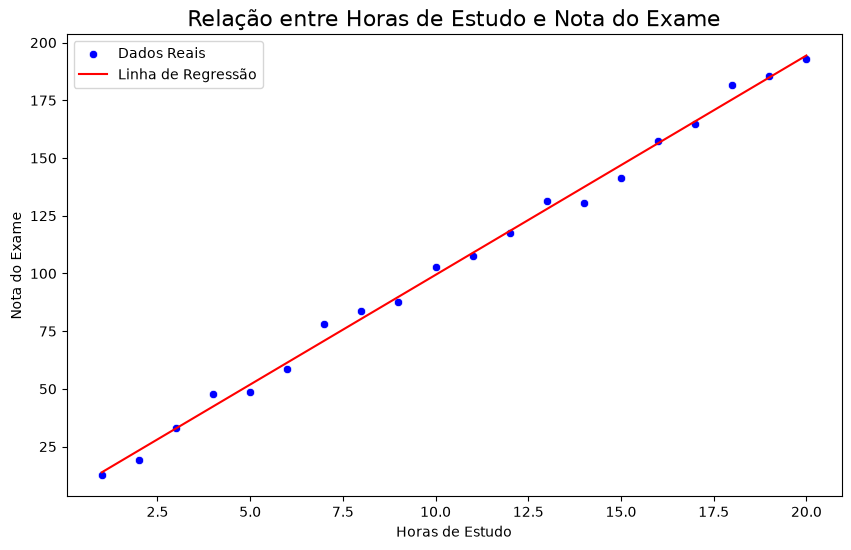

In [17]:
# Plotando os dados reais, isto é, as horas de estudo versus as notas do exame sem incluir o modelo

# criando uma variável para salvar o gráfico
grafico_dados_reais, ax = plt.subplots(figsize=(10, 6)) # definindo o tamanho do gráfico
sns.scatterplot(
    x='Horas de Estudo', 
    y='Nota do Exame', 
    data=df, 
    color='blue', 
    label='Dados Reais') #plotando o scatterplot
sns.lineplot(
    x='Horas de Estudo', 
    y='Nota Prevista', # aqui estamos adicionando a coluna de notas previstas ao gráfico, que é a linha de regressão
    # quanto mais próximo a linha de regressão os pontos estiverem, melhor será o modelo
    data=df, 
    color='red', 
    label='Linha de Regressão') #plotando a linha de regressão
ax.set_xlabel('Horas de Estudo')
ax.set_ylabel('Nota do Exame')
ax.set_title('Relação entre Horas de Estudo e Nota do Exame', fontsize=16)
ax.legend()

# Salvando o gráfico em png
grafico_dados_reais.savefig('grafico_dados_reais.png') # salvando o gráfico em png

plt.show() # adicionando labels e legenda ao gráfico, e exibindo o gráfico
